# A/B Test Analysis: Does Moving a Game's First Gate Change Player Retention?

**Questions**
1. Did moving the first progression gate in the mobile game *Cookie Cats* from level 30 to level 40 change how many players come back after 1 day and after 7 days?
2. Is the difference real, or could it be random noise?
3. Which version should the company keep?

**Background:** *Cookie Cats* is a puzzle game by Tactile Entertainment. As players progress they hit "gates" that make them wait or pay before continuing. In this experiment, new players were randomly assigned to a version with the first gate at level 30 (control) or at level 40 (treatment).

**Data:** 90,189 players who installed the game during the test, from the DataCamp project *Mobile Games A/B Testing with Cookie Cats*.

**Tools:** Python, pandas, matplotlib, statsmodels, bootstrap resampling.

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower
from pathlib import Path

DEEP, DARK, MID, LIGHT, SOFT, PLUM = "#880E4F", "#D81B60", "#F48FB1", "#F8BBD0", "#E8A0BF", "#AD1457"   # pink palette
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "svg.fonttype": "none"})
Path("images").mkdir(exist_ok=True)

df = pd.read_csv("data/cookie_cats.csv")
print(df.shape)
print("missing values:", int(df.isna().sum().sum()), "| duplicate players:", int(df.userid.duplicated().sum()))
df.head()

(90189, 5)
missing values: 0 | duplicate players: 0


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


Each row is one player:

- `version`: `gate_30` (control) or `gate_40` (treatment)
- `sum_gamerounds`: game rounds played in the first 14 days after install
- `retention_1`: did the player come back 1 day after installing?
- `retention_7`: did the player come back 7 days after installing?

## 2. Checking the experiment before reading the results

Before comparing outcomes I check that the test was run properly: are the two groups the size we would expect from a 50/50 split, and is there anything odd in the data?

In [2]:
n = df.version.value_counts().sort_index()
print(n.to_string())
chi2, p_srm = stats.chisquare(n.values)
print(f"\nshare in gate_40: {n['gate_40'] / n.sum():.2%}")
print(f"sample ratio mismatch test (chi-square vs 50/50): p = {p_srm:.4f}")

version
gate_30    44700
gate_40    45489

share in gate_40: 50.44%
sample ratio mismatch test (chi-square vs 50/50): p = 0.0086


In [3]:
print(df.sum_gamerounds.describe(percentiles=[.25, .5, .75, .95, .99]).round(1).to_string())
print(f"\nplayers who never played a round: {(df.sum_gamerounds == 0).sum():,} ({(df.sum_gamerounds == 0).mean():.1%})")
print("\nfive highest round counts:")
print(df.nlargest(5, "sum_gamerounds")[["version", "sum_gamerounds", "retention_1", "retention_7"]].to_string(index=False))

count    90189.0
mean        51.9
std        195.1
min          0.0
25%          5.0
50%         16.0
75%         51.0
95%        221.0
99%        493.0
max      49854.0

players who never played a round: 3,994 (4.4%)

five highest round counts:


version  sum_gamerounds  retention_1  retention_7
gate_30           49854        False         True
gate_30            2961         True         True
gate_40            2640         True        False
gate_30            2438         True         True
gate_40            2294         True         True


Two things stand out.

**The split is not exactly 50/50.** 50.44% of players are in the gate 40 group. The gap is small, but with 90,000 players a chi-square test flags it (p = 0.009). This is called a sample ratio mismatch, and it can be a sign that something in the assignment or logging treated the two groups differently. The dataset does not include the intended split or any assignment logs, so I cannot check further. I continue with the analysis and list this as a limitation.

**One player has 49,854 rounds.** That is about 3,500 rounds a day for 14 days, roughly 17 times the next highest player, and almost certainly a bot or a logging error. I remove that one row. It does not affect retention rates, but it would distort the average number of rounds.

In [4]:
df = df[df.sum_gamerounds < 10000].copy()
reached30 = (df.sum_gamerounds >= 30).mean()
reached40 = (df.sum_gamerounds >= 40).mean()
print(f"players remaining: {len(df):,}")
print(f"played at least 30 rounds: {reached30:.1%} | at least 40 rounds: {reached40:.1%}")

players remaining: 90,188
played at least 30 rounds: 36.9% | at least 40 rounds: 30.4%


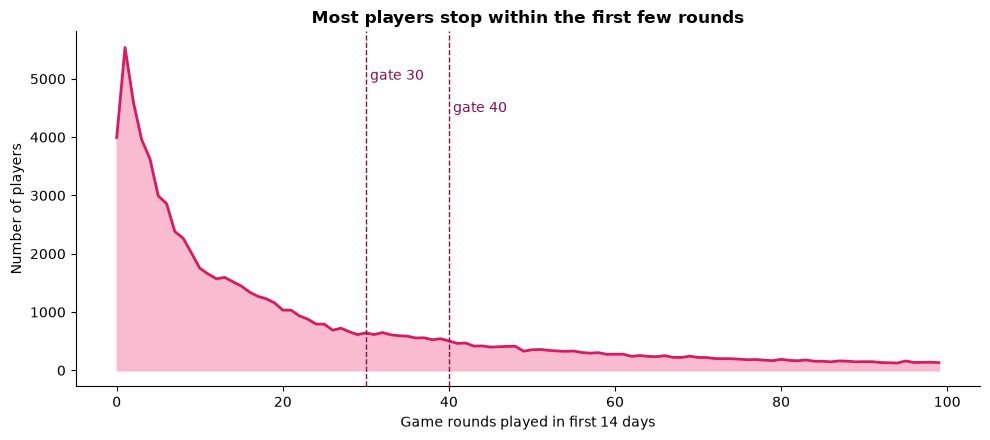

In [5]:
counts = df.groupby("sum_gamerounds").userid.count()
fig, ax = plt.subplots()
ax.plot(counts.index[:100], counts.values[:100], color=DARK, lw=2)
ax.fill_between(counts.index[:100], counts.values[:100], color=LIGHT)
for lvl in (30, 40): ax.axvline(lvl, color=DEEP, ls="--", lw=1)
ax.text(30.5, counts.max() * 0.9, "gate 30", color=DEEP); ax.text(40.5, counts.max() * 0.8, "gate 40", color=DEEP)
ax.set_xlabel("Game rounds played in first 14 days"); ax.set_ylabel("Number of players")
ax.set_title("Most players stop within the first few rounds")
plt.tight_layout(); plt.savefig("images/rounds_distribution.svg"); plt.show()

Most players leave quickly: half play 16 rounds or fewer and 4.4% install the game and never play. Only 37% play at least 30 rounds and 30% at least 40, so **most players never reach either gate**. Any effect of the gate has to come from the minority who get that far, which makes large differences in overall retention unlikely.

## 3. Retention by version

In [6]:
summary = df.groupby("version").agg(players=("userid", "size"), retention_1=("retention_1", "mean"),
                                    retention_7=("retention_7", "mean"), median_rounds=("sum_gamerounds", "median"),
                                    mean_rounds=("sum_gamerounds", "mean"))
print(summary.assign(retention_1=(summary.retention_1 * 100).round(2), retention_7=(summary.retention_7 * 100).round(2)).round(2).to_string())

         players  retention_1  retention_7  median_rounds  mean_rounds
version                                                               
gate_30    44699        44.82        19.02           17.0        51.34
gate_40    45489        44.23        18.20           16.0        51.30


## 4. Is the difference real? Two-proportion z-test

For each retention measure I test the null hypothesis that both versions have the same retention rate, and report a 95% confidence interval for the difference (gate 40 minus gate 30).

In [7]:
def compare(metric):
    g = df.groupby("version")[metric].agg(["sum", "size"])
    x40, n40, x30, n30 = g.loc["gate_40", "sum"], g.loc["gate_40", "size"], g.loc["gate_30", "sum"], g.loc["gate_30", "size"]
    z, p = proportions_ztest([x40, x30], [n40, n30])
    lo, hi = confint_proportions_2indep(x40, n40, x30, n30, compare="diff", method="wald")
    diff = x40 / n40 - x30 / n30
    return {"metric": metric, "gate_30": x30 / n30, "gate_40": x40 / n40, "diff_pts": diff * 100,
            "relative_change": diff / (x30 / n30) * 100, "ci_low": lo * 100, "ci_high": hi * 100, "z": z, "p_value": p}

tests = pd.DataFrame([compare("retention_1"), compare("retention_7")]).set_index("metric")
print(tests.round(4).to_string())

             gate_30  gate_40  diff_pts  relative_change  ci_low  ci_high       z  p_value
metric                                                                                    
retention_1   0.4482   0.4423   -0.5915          -1.3198 -1.2403   0.0572 -1.7871   0.0739
retention_7   0.1902   0.1820   -0.8183          -4.3028 -1.3263  -0.3103 -3.1574   0.0016


- **1-day retention** is 44.82% with the gate at 30 and 44.23% at 40, a difference of -0.59 percentage points. The confidence interval (-1.24 to +0.06) includes zero and p = 0.074, so this is **not statistically significant** at the 5% level.
- **7-day retention** is 19.02% at gate 30 and 18.20% at gate 40, a difference of **-0.82 percentage points** (95% CI -1.33 to -0.31, p = 0.002). This **is significant**, and stays significant after a Bonferroni correction for testing two metrics (threshold 0.025).

In relative terms, moving the gate to level 40 lowered 7-day retention by about 4.3%.

## 5. Bootstrap

The z-test relies on a formula. As a second opinion that makes no distributional assumptions, I bootstrap: resample players with replacement 10,000 times, recompute retention for each version each time, and look at the spread of the differences.

retention_1: mean diff -0.59 pts | 95% interval [-1.25, +0.06] | gate 30 ahead in 96.6% of resamples
retention_7: mean diff -0.82 pts | 95% interval [-1.33, -0.31] | gate 30 ahead in 99.9% of resamples


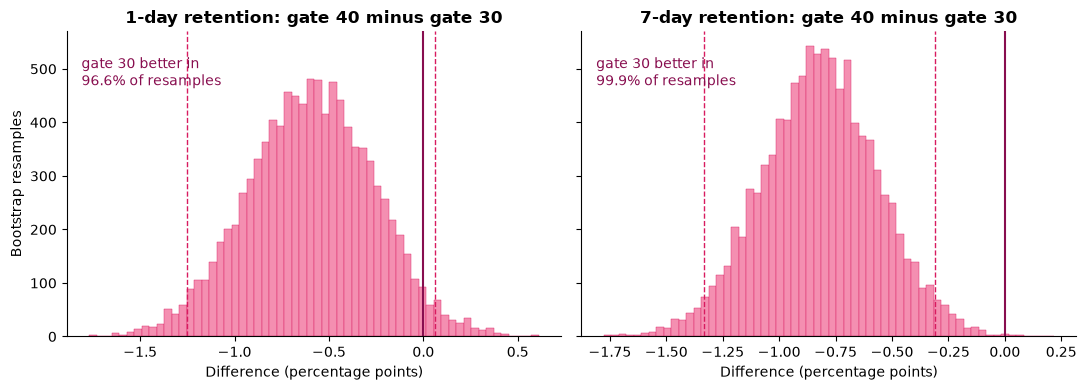

In [8]:
rng = np.random.default_rng(42)
B = 10_000
boot = {}
for metric in ("retention_1", "retention_7"):
    a = df.loc[df.version == "gate_30", metric].to_numpy()
    b = df.loc[df.version == "gate_40", metric].to_numpy()
    # resampling 0/1 outcomes with replacement is the same as drawing the number of successes from a binomial
    r30 = rng.binomial(len(a), a.mean(), B) / len(a)
    r40 = rng.binomial(len(b), b.mean(), B) / len(b)
    d = (r40 - r30) * 100
    boot[metric] = d
    print(f"{metric}: mean diff {d.mean():+.2f} pts | 95% interval [{np.percentile(d, 2.5):+.2f}, {np.percentile(d, 97.5):+.2f}] "
          f"| gate 30 ahead in {(d < 0).mean():.1%} of resamples")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metric, title in zip(axes, boot, ["1-day retention", "7-day retention"]):
    d = boot[metric]
    ax.hist(d, bins=60, color=MID, edgecolor=DARK, linewidth=0.3)
    ax.axvline(0, color=DEEP, lw=1.5)
    ax.axvline(np.percentile(d, 2.5), color=DARK, ls="--", lw=1); ax.axvline(np.percentile(d, 97.5), color=DARK, ls="--", lw=1)
    ax.set_title(f"{title}: gate 40 minus gate 30"); ax.set_xlabel("Difference (percentage points)")
    ax.text(0.03, 0.92, f"gate 30 better in\n{(d < 0).mean():.1%} of resamples", transform=ax.transAxes, color=DEEP, va="top")
axes[0].set_ylabel("Bootstrap resamples")
plt.tight_layout(); plt.savefig("images/bootstrap_differences.svg"); plt.show()

The bootstrap agrees with the z-test. For 7-day retention the 95% interval is -1.33 to -0.31 points and gate 30 came out ahead in 99.9% of resamples. For 1-day retention gate 30 was ahead in about 97% of resamples, but the interval just includes zero.

The 7-day result also makes more sense than the 1-day one: few players reach level 30 on their first day, so the gate position should matter more after a week than after a day.

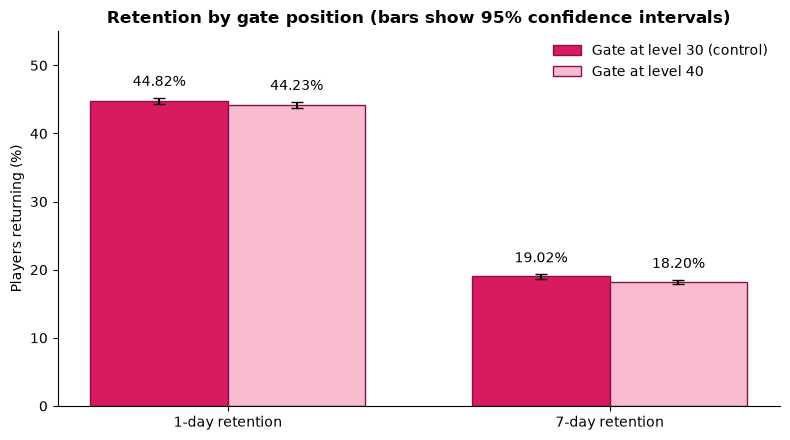

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2); w = 0.36
r30 = [summary.loc["gate_30", "retention_1"] * 100, summary.loc["gate_30", "retention_7"] * 100]
r40 = [summary.loc["gate_40", "retention_1"] * 100, summary.loc["gate_40", "retention_7"] * 100]
def se(p, n): return 1.96 * np.sqrt(p / 100 * (1 - p / 100) / n) * 100
e30 = [se(p, summary.loc["gate_30", "players"]) for p in r30]; e40 = [se(p, summary.loc["gate_40", "players"]) for p in r40]
b1 = ax.bar(x - w / 2, r30, w, yerr=e30, capsize=4, color=DARK, edgecolor=DEEP, label="Gate at level 30 (control)")
b2 = ax.bar(x + w / 2, r40, w, yerr=e40, capsize=4, color=LIGHT, edgecolor=DEEP, label="Gate at level 40")
ax.bar_label(b1, fmt="%.2f%%", padding=6); ax.bar_label(b2, fmt="%.2f%%", padding=6)
ax.set_xticks(x, ["1-day retention", "7-day retention"]); ax.set_ylabel("Players returning (%)"); ax.set_ylim(0, 55)
ax.set_title("Retention by gate position (bars show 95% confidence intervals)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("images/retention_by_version.svg"); plt.show()

## 6. Engagement: game rounds played

Rounds played is extremely skewed, so I compare the two versions with a Mann-Whitney U test (which compares ranks) instead of a t-test on means.

In [10]:
a = df.loc[df.version == "gate_30", "sum_gamerounds"]; b = df.loc[df.version == "gate_40", "sum_gamerounds"]
u, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"median rounds: gate_30 {a.median():.0f}, gate_40 {b.median():.0f} | mean: gate_30 {a.mean():.2f}, gate_40 {b.mean():.2f}")
print(f"Mann-Whitney U p-value: {p_mw:.4f}")
print(f"probability a random gate_30 player played more rounds than a random gate_40 player: {u / (len(a) * len(b)):.4f}")

median rounds: gate_30 17, gate_40 16 | mean: gate_30 51.34, gate_40 51.30
Mann-Whitney U p-value: 0.0509
probability a random gate_30 player played more rounds than a random gate_40 player: 0.5038


There is no clear difference in rounds played. The medians are 17 and 16, the means are almost identical (51.3), and the Mann-Whitney test is borderline (p = 0.051). A randomly chosen gate 30 player played more rounds than a randomly chosen gate 40 player 50.4% of the time, which is barely different from a coin flip.

## 7. How big a difference could this test detect?

A non-significant result only means something if the test was large enough to find a difference that matters.

In [11]:
power = NormalIndPower()
n30, n40 = summary.loc["gate_30", "players"], summary.loc["gate_40", "players"]
for metric in ("retention_1", "retention_7"):
    base = summary.loc["gate_30", metric]
    es = power.solve_power(nobs1=n30, ratio=n40 / n30, alpha=0.05, power=0.8)
    # convert Cohen's h back to a difference in proportions around the baseline
    mde = abs(np.sin(np.arcsin(np.sqrt(base)) - es / 2) ** 2 - base)
    print(f"{metric}: baseline {base:.1%}, minimum detectable difference at 80% power: {mde * 100:.2f} percentage points")

retention_1: baseline 44.8%, minimum detectable difference at 80% power: 0.93 percentage points
retention_7: baseline 19.0%, minimum detectable difference at 80% power: 0.73 percentage points


With about 45,000 players per group, the test could reliably detect differences of roughly 0.9 points in 1-day retention and 0.7 points in 7-day retention. The observed 1-day difference (0.59 points) is smaller than that, so the test cannot rule a small 1-day effect in or out. The observed 7-day difference (0.82 points) is above the threshold.

## 8. Conclusions

**Findings**

1. Moving the first gate from level 30 to level 40 **lowered 7-day retention** from 19.02% to 18.20% (-0.82 points, 95% CI -1.33 to -0.31, p = 0.002). The bootstrap gives the same answer.
2. The effect on 1-day retention points the same way (-0.59 points) but is not statistically significant (p = 0.074).
3. There is no clear difference in the number of rounds played.

**Recommendation:** keep the gate at level 30. There is no evidence that moving it to level 40 helps on any measure, and good evidence that it hurts 7-day retention. A plausible explanation is that an earlier gate forces a break before players get bored, so they come back wanting more.

**How much does it matter?** The difference is small in percentage points, but at scale it adds up: for every 100,000 installs, the level 30 gate keeps about 820 more players active after a week.

**Limitations**

- **Sample ratio mismatch.** The groups are 49.56% and 50.44% of players, which a chi-square test flags (p = 0.009). I could not investigate the cause with this data, so the results should be read with some caution.
- **Retention is not revenue.** The data has no information on in-app purchases. A later gate could still earn more per player even with lower retention.
- **Only two time points.** Retention is measured at day 1 and day 7. The effect at day 30 or later is unknown.
- **One removed outlier.** A single player with 49,854 rounds was dropped as a likely bot or logging error.
- **No player characteristics.** With no data on device, country or acquisition channel, I cannot check whether the groups were balanced or whether the effect differs between types of player.